# SPACEc: Clustering

After preprocessing the single cell data, the next step is to assign cell types. One of the most common approaches to identify cell types is unsupervised or semi-unsupervised clustering. SPACEc utilizes the widely used scanpy library or pyFlowSOM to carry out this task, aided by quality control functions that are specifically designed for inspecting spatial data.
The user can specify different clustering resolutions as well as the number of nearest neighbors to modify the number of identified clusters. The flexible design of SPACEc allows for the selection of unique clustering strategies, dependent on the research question and available dataset.

If you work with very large datasets, GPU-accelerated leiden clustering (`sp.tl.clustering(..., clustering="leiden_gpu")`, via RAPIDS) can still give a meaningful speedup on top of the default CPU path -- check our GitHub page for installation instructions. This is a separate, optional step from the `flavor="igraph"` used below: `igraph` is the default, faster CPU implementation and needs no extra setup, while GPU clustering is worth reaching for once your dataset is large enough that even that isn't fast enough.

In [ ]:
# import spacec first
import spacec as sp

#import standard packages
import os
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from IPython.display import display

# silencing warnings
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

plt.rc('axes', grid=False)  # remove gridlines
sc.settings.set_figure_params(dpi=80, facecolor='white') # set dpi and background color for scanpy figures

In [ ]:
# Apply SPACEc presentation style to all plots in this notebook.
sp.pl.set_style(sp.pl.SPACEcStyle.presentation())

In [ ]:
# Specify the path to the data
data_path = "path/to/example_data/raw/"
output_dir = "path/to/output/"
fig_dir = output_dir + "figures/"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

In [ ]:
# Loading the annotated anndata written by 03.1_preprocessing.ipynb
adata = sc.read(output_dir + 'adata_nn_demo_tonsil.h5ad')
adata # check the adata

## Optional: add morphology and contact features

This section computes a small set of shape and contact descriptors per cell from the segmentation mask
and adds them to `adata.obs`, as additional signal to consult during phenotyping. This can be helpful
when some marker signal is of medium quality or certain cells are stained nonspecifically.

`circularity`, `axis_ratio`, and `solidity` are derived directly from morphology columns already
sitting in `adata.obs` (written by `sp.tl.cell_segmentation()` in 02_cell_segmentation) -- no mask needed for those three.
`extent` and `n_contacts` need the segmentation mask, so we load the mask-only tif files
saved at the end of the segmentation tutorial (`02_cell_segmentation`).

For each cell:
- **circularity** — how close the cell's shape is to a perfect circle
  (`4π·area/perimeter²`, 1.0 = perfect circle). Low values flag elongated or irregular shapes.
- **axis_ratio** — ratio of the shorter to longer axis of the best-fit ellipse (minor/major).
  Close to 1 = round, close to 0 = elongated.
- **extent** — fraction of the cell's bounding box actually filled by the cell
  (area / bounding-box area). Low values indicate a shape that sits diagonally or irregularly
  within its bounding box.
- **solidity** — fraction of the convex hull actually filled by the cell
  (area / convex-hull area). Low values indicate a concave, notched, or fragmented shape.
- **n_contacts** — number of distinct neighboring cells this cell directly touches (shared mask
  boundary, no diagonals).


In [ ]:
FEATURE_COLS = ["circularity", "axis_ratio", "extent", "solidity", "n_contacts"]

mask_paths = {
    "reg001": output_dir + "tonsil1_mask.tif",
    "reg002": output_dir + "tonsil2_mask.tif",
}
masks = sp.hf.hf_load_masks(mask_paths)
adata = sp.hf.hf_attach_masks(adata, masks) # needed by sp.pl.feature_outlier_grid/expression_on_masks below


In [ ]:
adata = sp.tl.add_morphology_features(adata, masks, feature_cols=FEATURE_COLS)
adata.obs[FEATURE_COLS].describe()


Sanity-check each feature's distribution against a real example from each end: the histogram on
the left, and a DAPI crop of the lowest- and highest-scoring cell.

In [ ]:
# Load each region's DAPI channel by name (robust to channel order, unlike hardcoding an index)
region_tif_paths = {
    "reg001": output_dir + "reg001_X01_Y01_Z01.tif",
    "reg002": output_dir + "reg002_X01_Y01_Z01.tif",
}
dapi_imgs = {
    region: sp.hf.hf_load_image_dict(path, data_path + "channelnames.txt", nuclei_channel="DAPI")["DAPI"]
    for region, path in region_tif_paths.items()
};

In [ ]:
fig = sp.pl.feature_outlier_grid(adata, dapi_imgs, FEATURE_COLS)
display(fig)

## Clustering

By setting a clustering seed you can ensure that clustering gives the same result on every run. This is important if you want to change or correct things later on.

**NOTE**: **Expect different cluster numbers.** The seed makes clustering repeatable on **your** machine and environment. The annotation dictionaries below are **the authors' example**: build your own from the dotplots (or use automatic annotation suggestion `sp.tl.suggestuggest_annotation`), or load the reference annotation to follow the rest of the tutorials exactly.

In [ ]:
clustering_random_seed = 0

Before you start to annotate your cells, try to develop a clustering strategy. Common approaches include:
- Start with a coarse annotation such as immune cell, tumor cell, etc. and then refine the clusters.
- Overcluster your dataset and then remerge split populations.

Depending on your dataset, you will often find yourself using a mixed approach. Best practice is to start clustering with a set of markers that best describes your cell types. Functional markers such as PD1 should therefore be used later if you refine your clusters. 
In this simple example, we will start with a fairly large collection of markers and employ several rounds of subclustering to improve the results over multiple iterations. 

In [ ]:
# This step can be long if you have large phenocycler images

# Use this cell-type specific markers for cell type annotation
marker_list = [
    'FoxP3', 'HLA-DR', 'EGFR', 'CD206', 'BCL2', 'panCK', 'CD11b', 'CD56', 'CD163', 'CD21', 'CD8', 
    'Vimentin', 'CCR7', 'CD57', 'CD34', 'CD31', 'CXCR5', 'CD3', 'CD38', 'LAG3', 'CD25', 'CD16', 'CLEC9A', 'CD11c', 
    'CD68', 'aSMA', 'CD20', 'CD4','Podoplanin', 'CD15', 'betaCatenin', 'PAX5', 
    'MCT', 'CD138', 'GranzymeB', 'IDO-1', 'CD45', 'CollagenIV', 'Arginase-1']

# marker_list above only contains lineage markers. Everything else in the panel is
# a functional marker (activation, proliferation, exhaustion, etc.), useful to keep an eye on
# during lineage annotation even though they weren't used to drive clustering.
functional_markers = [m for m in adata.var_names if m not in marker_list]

# clustering
adata = sp.tl.clustering(
    adata, 
    clustering='leiden', # can choose between leiden and louvian
    n_neighbors=10, # number of neighbors for the knn graph
    resolution = 1, #clustering resolution (higher resolution gives more clusters)
    reclustering = False, # if true, don't recompute the neighbor-graph, only cluster (saves time if graph is already present)
    marker_list = marker_list, #if it is None, all variable names are used for clustering
    seed=clustering_random_seed, # random seed for clustering - reproducibility
    flavor='igraph', # faster leiden implementation (passed through to sc.tl.leiden)
)

Visualizing your results as UMAP scatter plot helps to identify batch effects and to estimate how well clusters are separated. What we want to see is poor separation between the regions (right) and good separation between the clusters (left). 

In [ ]:
# visualization of clustering with UMAP
sp.pl.umap(adata, color = ['leiden_1', 'unique_region'], wspace=0.5);

This plot shows the marker expression profile per cluster to help you assign phenotypes to clusters. If cluster identity is unclear, you can subcluster: split a cluster into a number of subclusters, to enhance clustering resolution for this specific subset of cells.

In addition to the markers used to cluster, the plot also optinally shows morphological features and quality control flags, as well as markers not used in clustering. Use this extra information when you are unsure about cluster identity based on only the clustering markers.

In [ ]:
QC_FLAG_COLS = ["qc_flag_low_dapi", "qc_flag_low_size", "qc_flag_large_size", "qc_flag_noise"]

# shorten variable names for improved readability.
QC_LABEL_OVERRIDES = {
    "qc_flag_low_dapi": "low_dapi",
    "qc_flag_low_size": "low_size",
    "qc_flag_large_size": "large_size",
    "qc_flag_noise": "noisy",
    "n_contacts": "contacts",
}

fig = sp.pl.extended_dotplot(
    adata, 'leiden_1',
    clustering_markers=marker_list, # The list of markers used for clustering
    extra_markers=functional_markers, # additional markers shown. Add markers here that were not used in clustering for any reason, 
    # such as low quality or because they are functional markers. markers are looked for in adata.X
    obs_continuous=FEATURE_COLS, # morphological features (or any continuous features).
    # see "Optional: add morphology and contact features" above for full definitions. columns are looked for in adata.obs
    obs_flags=QC_FLAG_COLS, # quality control flags, see tutorial 03.1_preprocessing. columns are looked for in adata.obs
    label_overrides=QC_LABEL_OVERRIDES, # shorter names for plotting
    dendrogram=True, # whether to plot a dendrogram to show cluster relationships.
) 

### Subclustering round 1
Clusters that have a mixed signal in the dotplot above can be split into smaller and prospectively more biologically coherent subclusters.

`sp.tl.subclustering()` replaces a hand-written chain of `sc.tl.leiden(restrict_to=...)` calls with a single call: pass the list of clusters to split and it splits them sequentially, one at a time, writing every result into one `key_added` column (`leiden_1_subcluster` here) so you no longer have to track which key each successive call should restrict on.

In [ ]:
# Subclustering round 1: split mixed clusters from leiden_1 one at a time.
# the result lands in adata.obs['leiden_1_subcluster'].
sp.tl.subclustering(
    adata,
    'leiden_1',
    ['0', '1', '3', '7', '11', '12', '14', '16', '17', '20'],
    resolution=0.3, # resolution for subclustering
    seed=clustering_random_seed, # random seed for clustering - reproducibility
    notes='split mixed clusters from round 1',
)

In [ ]:
# Visualize cluster expression profiles 
fig = sp.pl.extended_dotplot(
    adata, 'leiden_1_subcluster', # The cluster column (now use the subcluster column)
    clustering_markers=marker_list,
    extra_markers=[],
    obs_continuous=FEATURE_COLS,
    obs_flags=QC_FLAG_COLS,
    label_overrides=QC_LABEL_OVERRIDES,
    dendrogram=True, 
)

### Intermediate patch- or region-level cluster inspection

If, at any point, you are uncertain about the identity of a cluster, you can execute the following cells to inspect the cluster in its spatial context. 
- Use `sp.pl.extended_dotplot()` with `highlight_cluster` and/or `spatial_region` set to subset the dataset to a single region and highlight the cluster of interest on it. 
- Use `sp.pl.patch_QC()` to inspect cells in small spatial snapshots. This way, you can observe the direct neighborhood of the cells as well as where marker expression is localised. This function requires loading a subset of example images and optionally the segmentation mask.

Here we will look at cluster `16,0`. 

In [ ]:
cluster = '16,0'

#### Highlight clusters and subset the dotplot for a single region
You can inspect a single cluster's spatial distribution directly from the dotplot, without a separate spatial plotting call — pass `highlight_cluster` to outline that cluster's row and `spatial_region` to add a panel showing exactly where those cells sit within one region.

In [ ]:
dotplot_round1 = sp.pl.extended_dotplot(
    adata, 'leiden_1_subcluster',
    clustering_markers=marker_list, # The list of markers used for clustering
    extra_markers=functional_markers, # additional markers shown: empty here to allow space for spatial plot 
    obs_continuous=FEATURE_COLS, # circularity/axis_ratio/extent/solidity (shape regularity, 1.0=round/regular) + n_contacts (# touching neighbor cells) -- see "Optional: add morphology and contact features" above for full definitions
    obs_flags=QC_FLAG_COLS,
    label_overrides=QC_LABEL_OVERRIDES,
    dendrogram=True, dendrogram_position="after_markers",
        highlight_cluster=['16,0', '5'], # any cluster label(s) from leiden_1
    spatial_region='reg001', # any region in adata.obs['unique_region']
    flag_small_clusters=True,
)

If this creates a very wide plot that is hard to read, you can either save it and inspect in an external viewer, remove parts of the panel by passing empty lists, or reshape the spatial scatterplot.

In [ ]:
# uncomment to save the above figure to your fig_dir: 
# dotplot_round1.savefig(f"{fig_dir}/dotplot_round1.png", dpi=300) 

In [ ]:
# alternatively, plot a reduced version by passing empty lists
dotplot_round1_minimal = sp.pl.extended_dotplot(
    adata, 'leiden_1_subcluster',
    clustering_markers=marker_list[:25], # The list of markers used for clustering. passing others than used in clustering will generate
    # a warning
    extra_markers=[], # additional markers shown: empty here to allow space for spatial plot 
    obs_continuous=[], # shape features: empty here to allow space for spatial plot  
    obs_flags=[], # QC features: empty here to allow space for spatial plot  
    label_overrides=QC_LABEL_OVERRIDES,
    dendrogram=False, # disable
        highlight_cluster='16,0', # any cluster label from the key passed.
    spatial_region='reg001', # any region in adata.obs['unique_region']
    spatial_width_inches=6, # narrower
) 

#### Spatial snapshots: inspect a cluster in its direct spatial context
Use this function to look at a number of cells and their direct neighborhood. This is especially useful to check if strange marker expression in your cluster of interest is due to spatial spillover, non-specific staining, or real signal. We recommend plotting 5 markers maximum. You can switch marker combinations freely, depending on your hypothesis of cluster identity.

In [ ]:
# '16,0' has expression for both epithelial and immune lineages. Let's check visually which population it belongs to.
markers_for_epithelial_immune_mix = [
    'panCK',    # epithelial
    'CD20',     # B cell
    'PAX5',     # B cell master transcription factor -- confirms B lineage specifically
    'HLA-DR',   # antigen presentation (DC / macrophage / B cell)
    'CD206',    # M2 macrophage / mannose receptor
]
markers_basic_lineage = [ # you can pass any list of markers, tune it to your hypothesis. This is a stable default for this dataset.
    'panCK',   # epithelial
    'CD45',    # leukocytes
    'CD68',    # macrophage / myeloid
    'CD31',    # endothelial / vessel
]

##### Select images/regions to use for patch QC
Please select a set of images you would like shown that are representative of your dataset. Select regions from different:
- batches
- experimental conditions
- quality levels/staining differences
- or with known artefacts.

The aim is to visualise signals that might be skewing your clustering. For TMA data, we recommend 2-6 images that the following cell will load once, so that subsequent calls to patch_QC run faster. For WSI, 1-2 individual tiles. The amount of images you can pre-load depends on the amount of free RAM on your system. Rule of thumb: a loaded image's RAM footprint is `n_channels * height * width * bytes_per_pixel`, regardless of the on-disk file size (which can be much smaller than this if the file is compressed) -- e.g. a 3000x3000px, ~60-channel, 8-bit TMA core is roughly 0.5GB in RAM, while a 9000x9000px, ~96-channel, 16-bit WSI tile is roughly 16GB. Keep the total preloaded footprint comfortably under your system's free RAM (leaving room for everything else running).

In [ ]:
# List the available regions and their source paths for selection below (no loading yet)
for region, path in region_tif_paths.items():
    print(f"{region}: {path}")

In [ ]:
from pathlib import Path

images_to_load = ['reg001', 'reg002']  # pick region keys from the list printed above
image_names = {'reg001': 'tonsil', 'reg002':'tonsilitis'}  # leave empty to default to each path's filename

# Reuse a persistent cache across re-runs of this cell:
# only load regions not already cached, and drop cached regions no longer in images_to_load.
_image_cache = globals().get('_image_cache', {})
for r in list(_image_cache):
    if r not in images_to_load:
        del _image_cache[r]
for r in images_to_load:
    if r in _image_cache:
        print(f"{r}: already cached, skipping reload")
    else:
        print(f"{r}: loading...")
        _image_cache[r] = sp.hf.hf_load_image_dict(region_tif_paths[r], data_path + "channelnames.txt", 
                                                   nuclei_channel="DAPI")

images = _image_cache

if not image_names:
    image_names = {r: Path(region_tif_paths[r]).stem for r in images_to_load}

In [ ]:
# the entire marker-patches / masks / whole-image-overview visualisation, once per selected image
for region in images:
    fig = sp.pl.patch_QC(
        adata, 'leiden_1_subcluster', # cluster column
        cluster, # cluster label to inspect (set above)
        markers_for_epithelial_immune_mix, 
        masks, 
        images,
        region=region, # region to plot
        image_names=image_names, # dict of image name: find name of 'region' to use as plot title.
        n_patches=10, # amount of patches to plot. 
        whole_image_mode='dots', # 'mask' renders the actual segmentation mask instead (slower, more literal)
    )

### Assigning cluster identity: annotation round 1
Once you feel ready for the first round of annotation you can generate a dictionary to rename each cluster with a biological name and pass it to `sp.tl.annotate_clusters()`.


If you are not sure about a cluster and need further subclustering to resolve mixed populations, give these clusters a placeholder name such as `recluster`. This marks them for the next subclustering round. Any cluster label you leave out of the dictionary keeps its existing annotation automatically (`annotate_clusters` defaults to `missing="keep"`), so later rounds only need to list the labels that changed instead of re-listing every already-annotated cell type.

#### Optional: auto-suggest a starting annotation

Instead of building the annotation dictionary entirely by eye, `sp.tl.suggest_annotation()` can propose a starting point: it z-scores each marker across clusters (so "high" means high *relative to the other clusters*, not high in absolute intensity) and scores each cell type in `marker_dict` as the mean z-score of its markers. A cluster is proposed as `"Unknown"` if its best score is too weak, or `"Mixed"` if the top two candidate cell types are too close to call. Nothing is written to `adata`: the result is a plain dictionary you can inspect, edit, and hand to `sp.tl.annotate_clusters()` exactly like the one below.

Two modes:
- `mode="auto"` (used below) returns the full proposal at once, silently.
- `mode="manual"` walks through the clusters one at a time, showing a per-marker z-score barplot and prompting you to decide, cluster by cluster: accept the proposal, mark it `Unknown`, type your own cell type, or -- if you also pass `masks`/`images` -- look at `sp.pl.patch_QC()` for that cluster before deciding. You can stop at any point (`q`/`quit`, keeping whatever was already decided) and pick up later by passing that partial result back in as `resume_dict`. It blocks on a text prompt per cluster, so it needs to run directly in a live notebook cell (not shown executed here for that reason) -- try `sp.tl.suggest_annotation(adata, 'leiden_1_subcluster', marker_dict, mode="manual", masks=masks, images=images)` yourself.

In [ ]:
# {cell type: defining markers}, based on your expectations of cell types in the data.
round1_marker_dict = {
    'B cell': ['CD20', 'PAX5', 'CD21', 'CXCR5', 'CD3'],
    'CD4+ T cell': ['CD3', 'CD4', 'CCR7', 'CD45'],
    'CD8+ T cell': ['CD3', 'CD8', 'GranzymeB', 'CD45'],
    'Epithelial cell': ['panCK', 'EGFR', 'betaCatenin', 'CD45'],
    'GCB': ['PAX5', 'CD20', 'BCL2', 'CD38'],
    'M1 Macrophage': ['CD68', 'CD11c', 'CD163', 'CD206'],
    'M2 Macrophage': ['CD163', 'CD206', 'Arginase-1', 'CD68'],
    'Mast cell': ['MCT', 'CD45'],
    'NK cell': ['CD56', 'CD16', 'CD3'],
    'Plasma cell': ['CD38', 'CD138', 'CD20'],
    'Treg': ['FoxP3', 'CD25', 'CD3', 'CD4'],
    'Vessel': ['CD31', 'CD34', 'Podoplanin', 'aSMA'],
    'cDC1': ['CLEC9A', 'IDO-1', 'HLA-DR'],
    'DC': ['CD11c', 'HLA-DR', 'CD68'],
    'Neutrophil': ['CD15', 'CD16', 'panCK', 'CD45'],
}

auto_mapping = sp.tl.suggest_annotation(
    adata,
    'leiden_1_subcluster', # the cluster column to propose labels for
    round1_marker_dict, # {cell type: markers}, scored by mean z-score across clusters
    mode='auto', # 'auto' returns the proposal directly; 'manual' walks through it cluster by cluster with a barplot + prompt
)
auto_mapping

`mode="manual"` example: the header shows which cluster you're on and an overall
progress bar (`[6/14]` here. The options panel on the right lists every choice 
available for this call; `show patches (p/patch)` only appears when `masks`/`images` 
were passed in. 

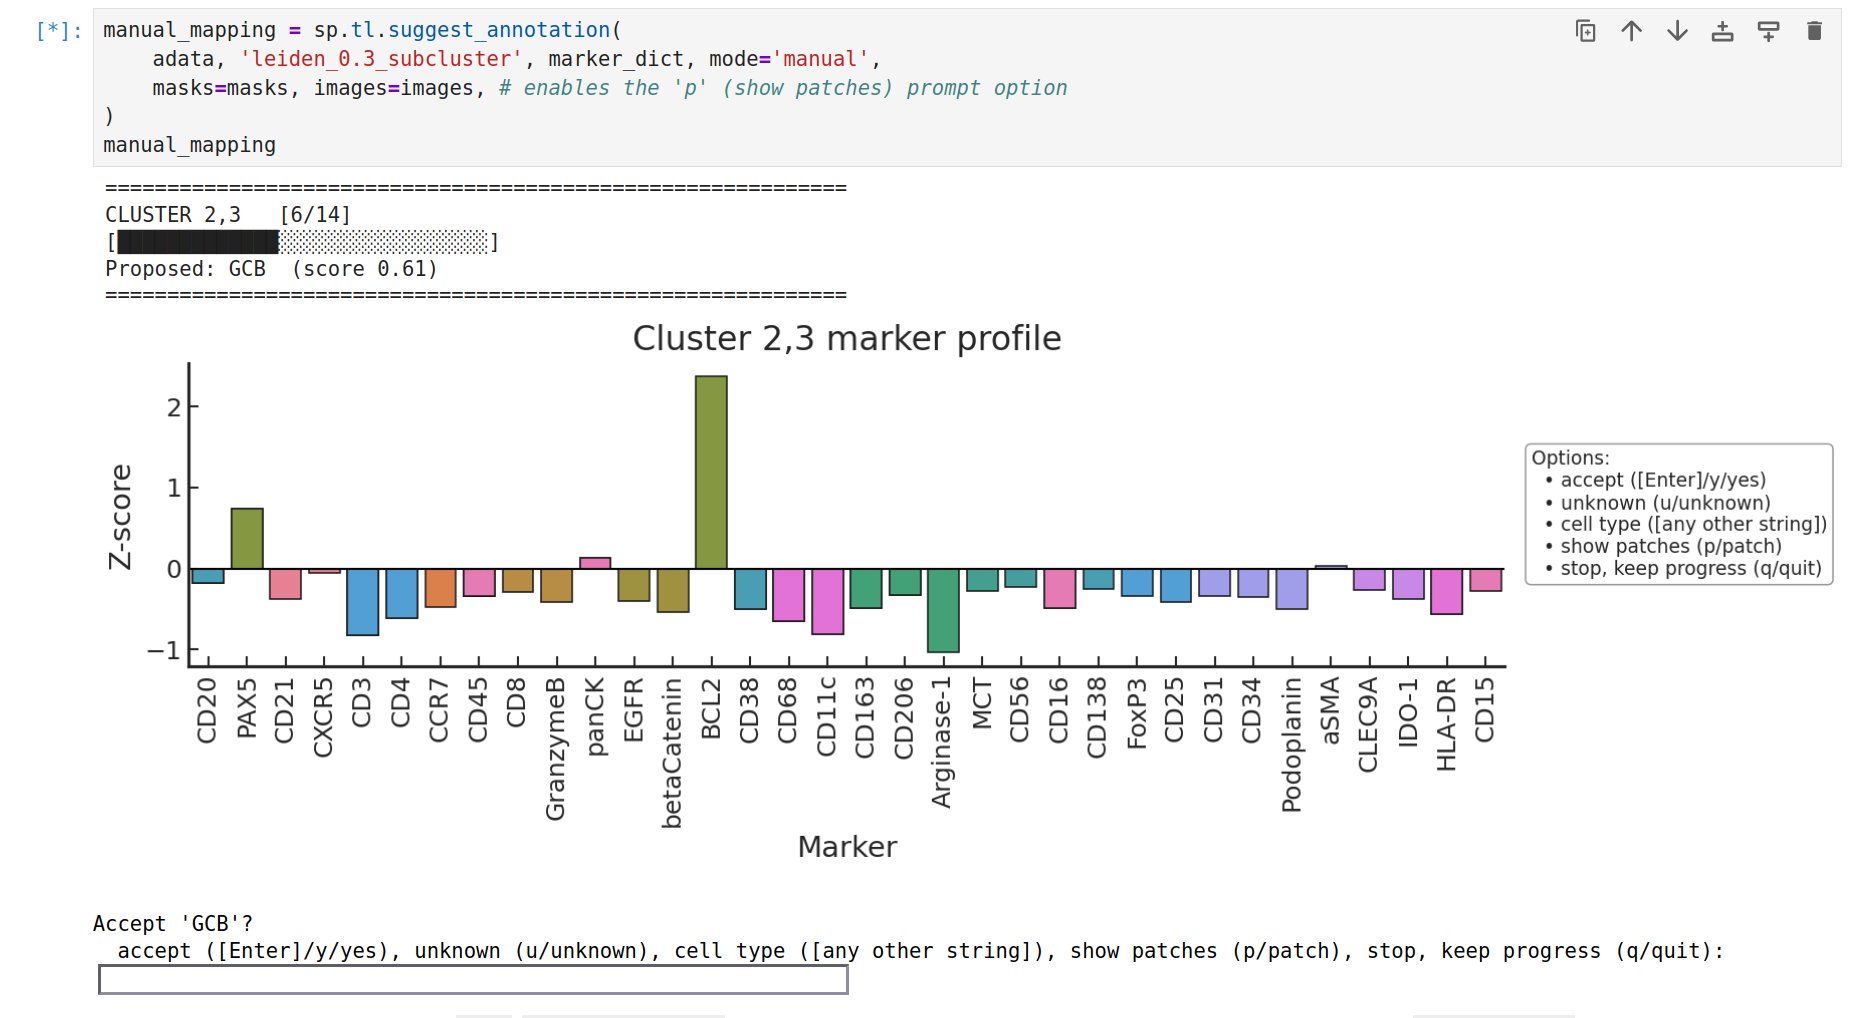



`auto_mapping` gets you partway, but a real annotation dictionary still needs a careful look at each cluster. Use the `mode="manual"` for per cluster review, including any patches, or revisit automatic annotation results using `sp.pl.extended_dotplot()` or `sp.pl.patch_QC()`.
The dictionary below is the result of that review.

In [ ]:
# We recommend defining a color palette here: we will use it for quality control visualisations from now on.
cell_type_colors = {
    'B cell' : '#1f77b4',           
    'CD4+ T cell' : '#ff7f0e',        
    'DC' : '#2ca02c',                
    'Vessel' : '#d62728',           
    'Epithelial cell' : '#9467bd',     
    'CD8+ T cell' : '#041f1e',     
    'GCB' : '#321325',               
    'Plasma cell' : '#5f0f40',      
    'M2 Macrophage' : '#bcbd22',     
    'Treg' : '#7f7f7f',            
    'cDC1' : '#17becf',             
    'M1 Macrophage' : '#e377c2',   
    'Mast cell' : '#f7dba7',          
    'NK cell' : '#000009',             
    'Neutrophil' : '#0ff4c6',           
    'PMN' : '#8c564b',                
}

In [ ]:
cluster_to_ct_dict = {
    '0,0': 'M1 Macrophage',  # CD68 dominant
    '0,1': 'recluster',
    '0,2': 'recluster',      # CD45/CD20/CD11c mixed
    '0,3': 'DC',              # CD11c dominant
    '0,4': 'recluster',      # CD68/CD20/PAX5 mixed
    '0,5': 'CD4+ T cell',    # CD3+CD4
    '1,0': 'NK cell',         # CD56 dominant
    '1,1': 'Vessel',          # Podoplanin/Vimentin (stromal)
    '1,2': 'recluster',
    '1,3': 'Vessel',          # aSMA (perivascular)
    '1,4': 'B cell',          # CD20/PAX5
    '1,5': 'Vessel',          # Vimentin/Podoplanin (stromal)
    '1,6': 'Vessel',          # aSMA/CD31 (perivascular/endothelial)
    '2': 'B cell',            # CD20/PAX5 despite Podoplanin spillover
    '3,0': 'recluster',      # CD11b/CD56 mixed, n=23 -- too small/ambiguous to call
    '4': 'B cell',            # CD20/PAX5 dominant -- no CD3/CD4 signal at all
    '5': 'recluster',        # HLA-DR/CD20 mixed, no panCK -- not epithelial
    '6': 'Plasma cell',       # CD138+CD38 (classic plasma cell combo)
    '7,0': 'recluster',      # weak/mixed CD34
    '7,1': 'Vessel',          # CD34+CD31 (endothelial)
    '7,2': 'recluster',      # CD138+CD34+CD31 mixed, n=61
    '7,3': 'Vessel',          # CD31 dominant
    '7,4': 'Vessel',          # CD31
    '8': 'GCB',               # weak, diffuse B-lineage signal (CD20/HLA-DR/PAX5) -- large cluster
    '9': 'B cell',            # CD20/CD21/PAX5 dominant -- CD20+ contradicts plasma cell
    '10': 'CD4+ T cell',      # CD3+CD4 dominant -- no vessel markers at all
    '11,0': 'recluster',     # B/T mixed
    '11,1': 'CD4+ T cell',   # CD3+CD4
    '11,2': 'recluster',     # weak signal overall
    '11,3': 'recluster',     # weak/mixed
    '11,4': 'CD4+ T cell',   # CD4/CD3
    '12,0': 'recluster',     # B/T/stromal/follicular all mixed
    '12,1': 'CD4+ T cell',   # CD3/CD4 (+CXCR5 -- Tfh-like)
    '12,2': 'B cell',         # CD20/CD21/CXCR5 (follicular B cell)
    '12,3': 'recluster',     # CD21+Podoplanin -- looks like follicular dendritic cell (FDC)
                               # stroma, not a cell type in this notebook's vocabulary yet
    '12,4': 'CD4+ T cell',   # CXCR5+CD3+CD4 (Tfh-like) -- no DC markers present
    '12,5': 'recluster',     # CD57 mixed with B/CXCR5 signal
    '12,6': 'GCB',            # CXCR5+CD20+CD21 (germinal-center-experienced B cell)
    '13': 'CD4+ T cell',      # CD3/CD4 dominant, very clean -- no CD20/PAX5 at all
    '14,0': 'CD4+ T cell',   # CD3/CD4/CD25
    '14,1': 'Treg',           # LAG3+CD25+FoxP3+CD4/CD3, n=24
    '14,2': 'recluster',     # Treg/DC signal mixed
    '14,3': 'CD4+ T cell',   # CD3/CD4/CD25 strong, FoxP3 not in top signal here
    '14,4': 'Treg',           # FoxP3+CD25 -- cleanest Treg signature in the dataset
    '14,5': 'Treg',           # FoxP3+CD25+CD4/CD3
    '14,6': 'recluster',     # CD25+PAX5 mixed, n=18
    '15': 'recluster',       # B-skewed but mixed, no CD163/CD206 -- not M2 macrophage
    '16,0': 'recluster',     # B/epithelial/myeloid mix -- the patch_QC example above
    '16,1': 'B cell',         # CD45/CD20/PAX5 dominant
    '16,2': 'B cell',         # PAX5/CD20 co-dominant
    '16,3': 'B cell',         # CD20 dominant
    '17,0': 'recluster',     # CD38+CD21+Podoplanin -- FDC/GC-stroma-like, mixed
    '17,1': 'recluster',     # CD21+Podoplanin, weak
    '17,2': 'GCB',            # CD20+CD38+CD21 (germinal center B cell combo)
    '17,3': 'recluster',     # stromal/B mixed
    '18': 'CD8+ T cell',      # CD8+CD3 dominant
    '19': 'M2 Macrophage',    # CD163+CD206
    '20,0': 'recluster',     # CD20/panCK/betaCatenin mixed
    '20,1': 'B cell',         # CD20 dominant
    '20,2': 'Epithelial cell',  # EGFR+betaCatenin
    '20,3': 'Epithelial cell',  # EGFR dominant
    '20,4': 'Epithelial cell',  # betaCatenin+panCK
    '21': 'M2 Macrophage',    # CD206 dominant -- no epithelial marker at all
    '22': 'cDC1',              # CLEC9A+IDO-1 (canonical cDC1 combo)
    '23': 'DC',                # CCR7+HLA-DR+IDO-1 (mature/migratory DC)
    '24': 'Neutrophil',        # CD15+CD16 maxed -- panCK likely crypt-epithelium spillover
    '25': 'M2 Macrophage',    # Arginase-1 dominant
    '26': 'CD8+ T cell',       # GranzymeB dominant (some CD68 spillover)
    '27': 'Mast cell',         # MCT (mast cell tryptase) dominant
}

# This allows us to generate a new column named cell_type_coarse based on the leiden_1_subcluster column
sp.tl.annotate_clusters(adata, 'leiden_1_subcluster', cluster_to_ct_dict, key_added='cell_type_coarse')

### First QC

After the first round of annotation you should check your results.

1) Make sure that each cell type expresses the correct markers.
2) Check the spatial position of cell types (consider speaking to a domain expert if you are unsure about the tissue)
3) Check the frequencies of cells - do these numbers fit with the biology of your sample?

Try to take your time and evaluate each step carefully to achieve the best results. 

In [ ]:
# Check the marker expression of the annotated cell types
fig = sp.pl.extended_dotplot(
    adata, 'cell_type_coarse',
    clustering_markers=marker_list,
    extra_markers=functional_markers,
    obs_continuous=FEATURE_COLS,
    obs_flags=QC_FLAG_COLS,
    label_overrides=QC_LABEL_OVERRIDES,
    dendrogram=True, dendrogram_position="after_markers",
    palette = cell_type_colors, # user-defined palette
)

In [ ]:
sp.pl.catplot(
    adata, 
    color = "cell_type_coarse", # specify group column name here (e.g. celltype_fine)
    unique_region = "condition", # specify unique_regions here
    X='x', Y='y', # specify x and y columns here
    n_columns=2, # adjust the number of columns for plotting here (how many plots do you want in one row?)
    palette=cell_type_colors, #default is None which means the color comes from anndata.uns['cell_type_coarse_colors'], 
    # generated by earlier plotting calls (such as an UMAP)
    savefig=False, # save figure as pdf
    output_fname = "", # change it to file name you prefer when saving the figure
    output_dir=output_dir, # specify output directory here (if savefig=True)
    figsize= 17, # specify the figure size here
    size = 20) # specify the size of the points

In [ ]:
# print the frequencies of cell types
adata.obs['cell_type_coarse'].value_counts()

### Subclustering round 2

The clusters labeled `recluster` in round 1 are split further by `sp.tl.subclustering(adata, 'cell_type_coarse', 'recluster', ...)` below.

Repeat the previously conducted procedure. It might be necessary to do this multiple times, dependent on the size and complexity of your dataset as well as your staining quality.

In [ ]:
sp.tl.subclustering(
    adata,
    'cell_type_coarse',
    'recluster',
    resolution=1.5,
    seed=clustering_random_seed,
    key_added='cell_type_coarse_subcluster', # new column added to adata.obs
)

In [ ]:
fig = sp.pl.extended_dotplot(
    adata, 'cell_type_coarse_subcluster',
    clustering_markers=marker_list,
    extra_markers=[],
    obs_continuous=FEATURE_COLS,
    obs_flags=QC_FLAG_COLS,
    label_overrides=QC_LABEL_OVERRIDES,
    dendrogram=True,
    palette = cell_type_colors,
)

In [ ]:
# A few of the new recluster,N subclusters are still ambiguous by marker profile alone.
# QC them visually before annotating:
clusters_to_qc = ['recluster,13', 'recluster,20', 'recluster,21', 'recluster,28', 'recluster,30']
markers_for_qc = {
    'recluster,13': ['CD206', 'PAX5', 'panCK', 'CD20', 'CD45'],      # flat/mixed -- macrophage vs. B vs. epithelial?
    'recluster,20': ['CD3', 'CD4', 'CD206', 'panCK', 'CD45'],        # weakest signal of any round-2 cluster (max ~0.3)
    'recluster,21': ['CD3', 'CD4', 'CD20', 'CXCR5', 'Podoplanin'],   # large (n=606), richly mixed T/B/follicular/stromal
    'recluster,28': ['CD38', 'CD21', 'Podoplanin', 'CollagenIV', 'CD20'],  # FDC/GC-stroma-like combo, no label in our vocabulary
    'recluster,30': ['CD11c', 'CD3', 'CD4', 'CD25', 'FoxP3'],        # DC markers AND Treg markers both strong -- real mix?
}

# run_patch_QC batch-runs patch_QC across one or more clusters (image_paths/mask_paths let it
# load any region on demand that isn't already in masks/images, e.g. if the cluster you pick
# needs a region beyond the ones pre-loaded above).
results = sp.pl.run_patch_QC(
    adata, 'cell_type_coarse_subcluster', clusters_to_qc,
    markers_for_qc, masks, images,
    image_paths=region_tif_paths, mask_paths=mask_paths,
    n_patches=10,
    whole_image_mode='dots', # 'mask' renders the actual segmentation mask instead (slower, more literal)
    palette=cell_type_colors, # 
)

# Only 2 of these 5 figures are rendered inline as an example.
# Comment out the snippet below to see them all.
keep = {'recluster,13', 'recluster,20'}
for cluster, region_figs in results.items():
    for fig in region_figs.values():
        if cluster not in keep:
            plt.close(fig)

In [ ]:
# tentative annotation based on the marker and patch_QC check above for the ambiguous ones

# unlisted labels (already-annotated cell types from round 1) keep their
# existing annotation automatically -- annotate_clusters() defaults to
# missing="keep" -- so only the newly split 'recluster,N' labels need an
# entry here.
cluster_to_ct_dict = {
    'recluster,0': 'recluster',       # CollagenIV/CD206/CD4/CD45/CD20/panCK all moderate -- flat mix
    'recluster,1': 'recluster',       # weak/mixed B+T signal
    'recluster,2': 'B cell',          # PAX5 dominant, despite panCK/CD206 spillover
    'recluster,3': 'Vessel',          # Vimentin+aSMA (stromal/perivascular)
    'recluster,4': 'recluster',       # weak, no dominant marker
    'recluster,5': 'recluster',           # weak/mixed, n=17
    'recluster,6': 'recluster',       # BCL2-dominant only -- non-specific
    'recluster,7': 'B cell',          # CD20 dominant
    'recluster,8': 'B cell',          # CD20/PAX5/HLA-DR combo
    'recluster,9': 'B cell',          # CD20+CXCR5+PAX5 (follicular B)
    'recluster,10': 'recluster',      # weak overall, CD4 leads but not convincingly
    'recluster,11': 'recluster',      # CD3/CD4 vs CD20/CXCR5 comparable -- genuine T/B mix
    'recluster,12': 'B cell',         # HLA-DR + CD20/PAX5
    'recluster,13': 'recluster',      # flat mix (BCL2/CollagenIV/CD206/PAX5/panCK all moderate) -- NOT epithelial, see QC cell above
    'recluster,14': 'recluster',      # mixed, no dominant marker
    'recluster,15': 'B cell',         # CD20/PAX5 substantial despite spillover
    'recluster,16': 'recluster',      # CD20 vs Podoplanin comparable -- B/stromal mix
    'recluster,17': 'recluster',      # CD20 vs Podoplanin comparable -- B/stromal mix
    'recluster,18': 'DC',             # CD11c dominant
    'recluster,19': 'Vessel',         # Vimentin dominant, stromal
    'recluster,20': 'recluster',      # weakest signal of any cluster here (max 0.32) -- NOT M2 macrophage, see QC cell above
    'recluster,21': 'recluster',      # everything elevated (CD3/CXCR5/CD21/CD4/Podoplanin/CD20) -- rich T/B/follicular/stromal mix
    'recluster,22': 'Epithelial cell',  # betaCatenin+panCK+EGFR -- NOT CD8+ (CD8/CD3 not even in top 8)
    'recluster,23': 'Vessel',         # CD34+CD31 (endothelial)
    'recluster,24': 'recluster',      # CD11c+CD68 comparable -- DC/macrophage mix
    'recluster,25': 'DC',             # CD11c dominant
    'recluster,26': 'recluster',      # CD57+CXCR5 (unusual combo, mixed with CD3/CD20)
    'recluster,27': 'DC',             # CD11c+HLA-DR
    'recluster,28': 'recluster',      # CD38+CD21+Podoplanin -- FDC/GC-stroma-like, no label in our vocabulary
    'recluster,29': 'recluster',      # CD138+CD34+CD31 mixed, n=61 -- plasma cell + endothelial markers together
    'recluster,30': 'recluster',      # CD11c AND CD3/CD4/CD25/FoxP3 all strong -- DC/Treg mix, genuinely unusual
    'recluster,31': 'recluster',      # CD25+CD4 but no FoxP3 in top 8, n=18 -- too small/ambiguous
    'recluster,32': 'Noise',          # CD11b+CD56+GranzymeB mixed, n=23 -- myeloid/NK/cytotoxic combo: suspicious, will inspect below
                                      # before removing as Noise
}

sp.tl.annotate_clusters(adata, 'cell_type_coarse_subcluster', cluster_to_ct_dict, key_added='cell_type_coarse_f')

In [ ]:
fig = sp.pl.extended_dotplot(
    adata, 'cell_type_coarse_f',
    clustering_markers=marker_list,
    extra_markers=functional_markers,
    obs_continuous=[],
    obs_flags=QC_FLAG_COLS,
    label_overrides=QC_LABEL_OVERRIDES,
    dendrogram=True,
    palette=cell_type_colors
)

In [ ]:
# print the frequencies of cell types
adata.obs['cell_type_coarse_f'].value_counts()

#### Removing noisy cells
If you encounter a cell population that seems to be impossible to annotate, check whether its cells resemble noise or a segmentation artefact before you remove anything. Above, we set a cluster to 'Noise'. Let's inspect whether we want to remove it. 
1. Use `sp.pl.cluster_qc()` to take a closer look at the properites behind the QC flags shown in the `sp.pl.extended_dotplot()` "% flagged in QC" block: compare the cell size and DAPI brightness distributions against other clusters, so you can see at a glance whether one population stands apart from all the others.
2. Use `sp.pl.run_patch_QC()` to visually check these outlier clusters: does their shape or marker expression look like an artefact?

Once you are sure that a cluster does not contain real cells, set it as 'Noise' and remove it from the dataset. 

In [ ]:
# Before dropping anything: how does the suspicious population compare to every
# other cluster on the properties that were measured for each cell?
_, qc_table = sp.pl.cluster_qc(
    adata,
    'cell_type_coarse_f',      # the cluster / cell type column to compare
    highlight_cluster='Noise', # draw this one in red; purely cosmetic
    return_data=True,          # also hand back the per-cluster median table
    features=['DAPI', 'area', 'n_contacts'] # optional: if not set, plots all numeric columns in obs (except IDs and coordinates).
)

In [ ]:
cluster = 'Noise'
markers_for_noise = ['CD11b', 'CD56', 'CD11c', 'GranzymeB', 'CD206']  # this cluster's top markers

# Rare cluster (23 cells total): use patch_QC with region=None
# so the function can automatically pick the regions where this cluster occurs.
fig = sp.pl.patch_QC(
    adata, 'cell_type_coarse_f', cluster,
    markers_for_noise,
    masks,
    images,
    region=None, # so it is automatically picked for this rare cluster.
    n_patches=10,
    whole_image_mode='dots',
)

In this dataset the `Noise` population sits above other clusters for DAPI, but marker expression and cell shapes are plausible. In this case, it is safer to keep and recluster the population. If instead the DAPI and size distributions had looked different from the other clusters and the `patch_QC` had indicated marker over-expression or segmentation issues, we would have removed it.

In [ ]:
# option 1: remove noise:
# adata = adata[~adata.obs['cell_type_coarse_f'].isin(['Noise'])]
# option 2: recluster/assign noise:
adata.obs['cell_type_coarse_f'] = (
    adata.obs['cell_type_coarse_f'].astype(str).replace('Noise', 'recluster').astype('category')
)

### subclustering round 3

Repeat the previous steps: `sp.tl.subclustering()` splits the `recluster` placeholder from round 2 into round 3's finer clusters, then `sp.tl.annotate_clusters()` maps only the newly split `recluster,N` labels -- everything already annotated keeps its label automatically.

In [ ]:
sp.tl.subclustering(
    adata,
    'cell_type_coarse_f',
    'recluster',
    resolution=1.5,
    seed=clustering_random_seed,
    key_added='cell_type_coarse_f_subcluster',
)

In [ ]:
fig = sp.pl.extended_dotplot(
    adata, 'cell_type_coarse_f_subcluster',
    clustering_markers=marker_list,
    extra_markers=[],
    obs_continuous=[],
    obs_flags=QC_FLAG_COLS,
    label_overrides=QC_LABEL_OVERRIDES,
    dendrogram=True,
)

Scaling your data can help boost contrast and make it easier to decide on difficult-to-annotate clusters.

In [ ]:
# scale and store results in layer
adata.layers["scaled"] = sc.pp.scale(adata, copy=True).X

In [ ]:
sc.pl.matrixplot(
    adata,
    marker_list,
    "cell_type_coarse_f_subcluster",
    dendrogram=False,
    colorbar_title="mean z-score",
    layer="scaled",
    vmin=-2,
    vmax=2,
    cmap="RdBu_r",
)

In [ ]:
# Only the newly split 'recluster,N' labels need an entry here.
cluster_to_ct_dict = {
    'recluster,0': 'B cell',        # PAX5=0.90 dominant
    'recluster,1': 'B cell',        # PAX5=0.73 leads
    'recluster,2': 'Unresolved',    # CD11c vs PAX5/CD20/CD68 all comparable -- DC/B/macrophage mix
    'recluster,3': 'B cell',        # PAX5=0.99, near-max
    'recluster,4': 'B cell',        # PAX5=0.92 dominant
    'recluster,5': 'B cell',        # PAX5+CD20+CXCR5 (follicular B combo)
    'recluster,6': 'Unresolved',    # CD25+CD4 but no FoxP3, n=18 -- too small/ambiguous
    'recluster,7': 'Unresolved',    # CD4 vs PAX5 genuinely tied
    'recluster,8': 'B cell',        # CD20=0.75 clearly leads
    'recluster,9': 'Unresolved',    # weak/mixed, nothing above 0.6
    'recluster,10': 'B cell',       # PAX5=0.63 leads
    'recluster,11': 'B cell',       # CD20=0.62 leads, HLA-DR/CXCR5 support follicular B
    'recluster,12': 'Unresolved',   # everything weak (max 0.31)
    'recluster,13': 'Unresolved',   # PAX5 leads but 5 other markers comparably elevated
    'recluster,14': 'B cell',       # PAX5=1.00, max
    'recluster,15': 'Unresolved',   # CD45/Podoplanin/BCL2/CD20/Vimentin all comparable -- B/stromal mix
    'recluster,16': 'B cell',       # PAX5=0.82 leads clearly
    'recluster,17': 'Unresolved',   # only non-specific BCL2 leads, PAX5 modest
    'recluster,18': 'CD4+ T cell',  # CD3+CD4 combo, CXCR5 (Tfh-like)
    'recluster,19': 'CD4+ T cell',  # CD3+CD4 dominant pair
    'recluster,20': 'B cell',       # PAX5=0.80 clearly elevated
    'recluster,21': 'CD4+ T cell',  # CD3/CD4/CXCR5 triad near-max (Tfh-like), despite B/stromal spillover
    'recluster,22': 'Unresolved',   # CD21+Podoplanin (FDC-like combo, no label in our vocabulary), mixed with T/B markers
    'recluster,23': 'Unresolved',   # everything weak (max CD4=0.45)
    'recluster,24': 'Unresolved',   # CD11c AND CD3/CD4/CD25/FoxP3 all strong -- DC/Treg mix, same unusual combo as round 2
    'recluster,25': 'B cell',       # CD45=CD20=1.00, CXCR5/HLA-DR support follicular B
    'recluster,26': 'Unresolved',   # CD57+CXCR5 (unusual combo, recurring from round 2), mixed with CD3/CD20
    'recluster,27': 'Unresolved',   # CD38+Podoplanin+CD21 -- FDC/GC-stroma-like, recurring, no label in our vocabulary
    'recluster,28': 'Unresolved',   # CD138+CD34+CD31 all maxed -- plasma cell + endothelial markers together
    'recluster,29': 'NK cell',      # the reclustered ex-'Noise' population -- CD11b+CD56 both near-max;
                                     # CD11b+CD56+ is a described NK cell subset
}

sp.tl.annotate_clusters(adata, 'cell_type_coarse_f_subcluster', cluster_to_ct_dict, key_added='cell_type')

In [ ]:
# Full lineage: which original Leiden cluster each cell type came from
sp.tl.clustering_tree(adata)

# Parameters of every clustering / subclustering / annotation step
sp.tl.clustering_report(adata)

In [ ]:
# drop noise
adata = adata[~adata.obs['cell_type'].isin(['Noise'])].copy()

### Final QC

As mentioned previously, careful reevaluation is the key for cell annotation. Before saving your data, check the annotation one more time.

In [ ]:
ax = sc.pl.heatmap(
    adata,
    marker_list,
    groupby="cell_type",
    layer="scaled",
    vmin=-2,
    vmax=2,
    cmap="RdBu_r",
    dendrogram=False,
    swap_axes=True,
    figsize=(40, 10),
)

In [ ]:
# store the annotated adata
adata.write(output_dir + "adata_nn_demo_annotated.h5ad")

## Single-cell visualization

In [ ]:
# list of cell types
adata.obs['cell_type'].value_counts()

In [ ]:
cell_type_colors["Unresolved"] =  '#d3d3d3'  # light grey, distinct from Tregs
sp.pl.catplot(
    adata, 
    color = "cell_type", # specify group column name here (e.g. celltype_fine)
    unique_region = "condition", # specify unique_regions here
    X='x', Y='y', # specify x and y columns here
    n_columns=2, # adjust the number of columns for plotting here (how many plots do you want in one row?)
    palette=cell_type_colors, #default is None which means the color comes from the anndata.uns that matches the UMAP
    savefig=False, # save figure as pdf
    output_fname = "", # change it to file name you prefer when saving the figure
    output_dir=output_dir, # specify output directory here (if savefig=True)
    figsize= 17,
    size = 20)

In [ ]:
# cell type percentage tab and visualization
ct_perc_tab, _ = sp.pl.stacked_bar_plot(
    adata = adata, # adata object to use 
    color = 'cell_type', # column containing the categories that are used to fill the bar plot
    grouping = 'condition', # column containing a grouping variable (usually a condition or cell group) 
    cell_list = ['GCB', 'Treg'],  # list of cell types to plot, you can also see the entire cell types adata.obs['celltype_fine'].unique()
    palette=cell_type_colors, #default is None which means the color comes from the anndata.uns that matches the UMAP
    savefig=False, # change it to true if you want to save the figure
    output_fname = "", # change it to file name you prefer when saving the figure
    output_dir = output_dir, #output directory for the figure
    norm = False, # if True, then whatever plotted will be scaled to sum of 1
    fig_sizing= (6,6)
)

In [ ]:
sp.pl.create_pie_charts(
    adata,
    color = "cell_type", 
    grouping = "condition", 
    show_percentages=False,
    palette=cell_type_colors, #default is None which means the color comes from the anndata.uns that matches the UMAP
    savefig=False, # change it to true if you want to save the figure
    output_fname = "", # change it to file name you prefer when saving the figure
    output_dir = output_dir #output directory for the figure
)

## Full spatial QC across final cell types

**Warning:** this cell renders one full `patch_QC` figure per cell type per selected region. With as many final cell types as this dataset ended up with, that can mean many large figures and take a long time to run. Output is suppressed below (each figure is closed right after rendering) so running this doesn't balloon the notebook file. See the commented block at the end of the cell for saving the figures to disk instead of just closing them.

In [ ]:
# per-cell-type marker panel (kept to the recommended <=5 markers each) for the final spatial QC
markers_per_cell_type = {
    'B cell': ['CD20', 'PAX5', 'CD21', 'CXCR5', 'CD3'],
    'CD4+ T cell': ['CD3', 'CD4', 'CCR7', 'CD45'],
    'CD8+ T cell': ['CD3', 'CD8', 'GranzymeB', 'CD45'],
    'Epithelial cell': ['panCK', 'EGFR', 'betaCatenin', 'CD45'],
    'GCB': ['PAX5', 'CD20', 'BCL2', 'CD38'],
    'M1 Macrophage': ['CD68', 'CD11c', 'CD163', 'CD206'],
    'M2 Macrophage': ['CD163', 'CD206', 'Arginase-1', 'CD68'],
    'Mast cell': ['MCT', 'CD45'],
    'NK cell': ['CD56', 'CD16', 'CD3'],
    'Plasma cell': ['CD38', 'CD138', 'CD20'],
    'Treg': ['FoxP3', 'CD25', 'CD3', 'CD4'],
    'Vessel': ['CD31', 'CD34', 'Podoplanin', 'aSMA'],
    'cDC1': ['CLEC9A', 'IDO-1', 'HLA-DR'],
    'DC': ['CD11c', 'HLA-DR', 'CD68'],
    'Neutrophil': ['CD15', 'CD16', 'panCK', 'CD45'],
    'Unresolved': ['CD45', 'panCK', 'CD3', 'CD20', 'HLA-DR'],  # broad lineage markers -- this bucket is heterogeneous by definition
}

results = sp.pl.run_patch_QC(
    adata, 'cell_type', adata.obs['cell_type'].unique().tolist(),
    markers_per_cell_type, masks, images,
    image_paths=region_tif_paths, mask_paths=mask_paths,
    n_patches=10,
    whole_image_mode='dots',
    palette=cell_type_colors,
)

# suppress inline output: close every figure instead of letting it render
for region_figs in results.values():
    for fig in region_figs.values():
        plt.close(fig)

# --- uncomment to save each figure to disk instead of discarding it ---
# results = sp.pl.run_patch_QC(
#     adata, 'cell_type', adata.obs['cell_type'].unique().tolist(),
#     markers_per_cell_type, masks, images,
#     image_paths=region_tif_paths, mask_paths=mask_paths,
#     n_patches=10,
#     whole_image_mode='dots',
#     palette=cell_type_colors,
#     out_dir=f"{output_dir}patch_QC_all_cell_types/",  # one PNG per cell type/region; figures are saved and closed automatically
# )